# **Explore Simple Image Filters** 

*(c) 2023 Barry Van Veen, AllSignalProcessing, LLC*

This notebook explores the concept of filtering images. We filter an image by computing the value of each pixel in the output image as a weighted sum of the values at neighboring pixels in the input image.  The weights are called the "point-spread function" of the filter.

In general filtering images is more complex to understand than filtering time signals and we recommend completing the Explore FIR Filtering activity before starting this one. 

You may begin by considering the effect of the filter on edges in the image. An edge is very similar to a transition in the step signal used in the Explore FIR Filtering activity.  The stop sign image used in this example has numerous vertical, horizontal, and diagonal edges and thus is a good example for interpreting the behavior of simple image filters.

In [21]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt 

from scipy.io import loadmat
from google.colab import drive
drive.mount('/content/drive')

# set default figure size and resolution
plt.rcParams['figure.figsize'] = [8, 8]
plt.rcParams['figure.dpi'] = 100

# load MATLAB file containing image data
# may need to change directory address depending on user configuration

path = '/content/drive/My Drive/Colab Notebooks/ASP/Foundations/stop_image.mat'

in_data = loadmat(path)

stopsign = in_data['stop']


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
def dispgrayimage(pict,text):
  # produces figure showing pict on square axes with grayscale colormap

  plt.axis('off')
  plt.imshow(pict,cmap='gray')
  plt.title(text)
  ax = plt.gca()
  ax.get_xaxis().set_visible(False)
  ax.get_yaxis().set_visible(False)
  plt.show()
  return

# Original Image

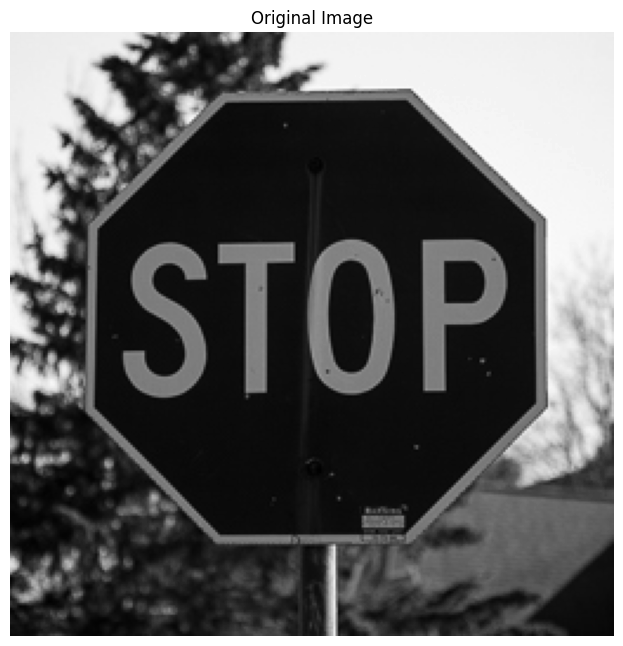

In [23]:
# display original image
dispgrayimage(stopsign, 'Original Image')


The values in this greyscale image are integers from 0 to 255.  Larger values correspond to brighter pixels while smaller values correspond to darker pixels.  Thus 0 is the darkest black while 255 is the brightest white.  Edges associated with the letters transition from a relatively small value representing the dark part of the sign to a large value representing the interior of the letter. Similar arrangements create the white outline of the sign.

# Apply averaging PSF to image


Averaging Point Spread Function
[[0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]]


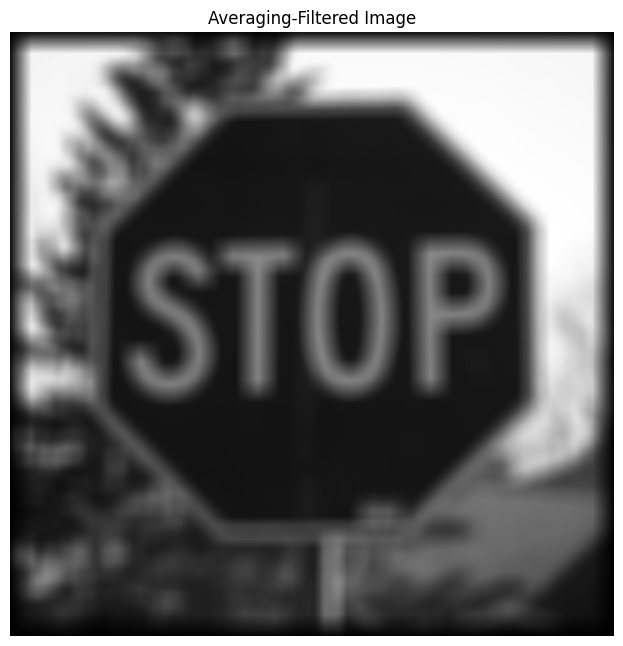

In [24]:
# moving average of 100 values; 10 horizontal by 10 vertical
psf_av = 0.01*np.ones((10,10))

print('Averaging Point Spread Function')
print(psf_av)

filt_av = signal.convolve2d(psf_av, stopsign, mode='full')

dispgrayimage(filt_av,'Averaging-Filtered Image')


Note that the point spread function indicates the value of each output pixel is the average of values of the 100 pixels in the 10 rows above and 10 columns to the left of the corresponding pixel in the input image.

1.   How did the filtering change the image?
2.   Can you explain why this filter (PSF) produced the change you see?

*The filter introduced blurring to the image.  Sharp edges are now gradual transition from dark to light. The edges are blurred because the PSF averages pixel values over a 10 row and 10 column region.  Near an edge there are small values (dark) and large values (light) that average to a middle value.  The constant portions of the image (sky and interior of the sign) don't change because averaging constant values produces a constant value. The interior of the letters are not changed because the image is constant (bright) over 10 rows and columns away from the edges of the letters.*


# Apply first differencing PSF to image



Differencing Point Spread Function
[[ 1.]
 [-1.]]


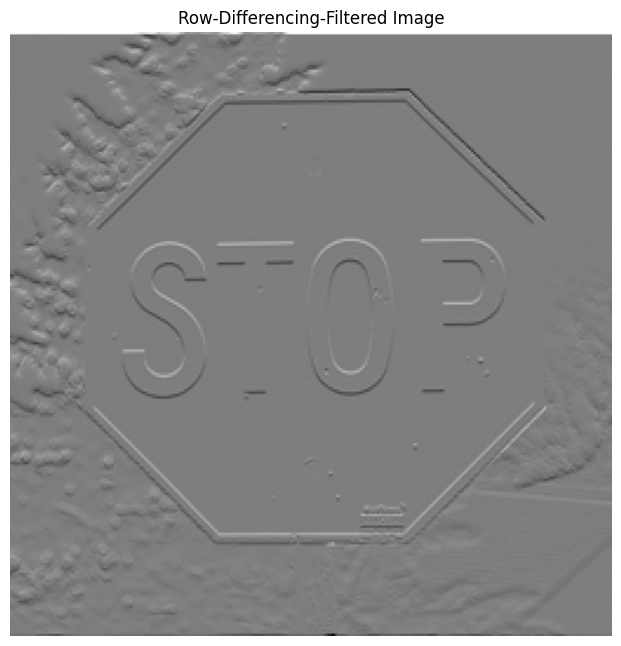

In [25]:
from numpy.lib.function_base import disp
# difference of rows
psf_dif1 = np.ones((2,1))

psf_dif1[1,0]=-1

print('Differencing Point Spread Function')
print(psf_dif1)

filt_dif1 = signal.convolve2d(psf_dif1, stopsign, mode='full')

dispgrayimage(filt_dif1,'Row-Differencing-Filtered Image')

The point-spread function here indicates that the value of each output pixel is given by the difference between the value of the corresponding input image pixel and that of the pixel above it.  That is, the differencing acts in the vertical direction, across the rows of the image. 

Note: the original image had all positive values, so differencing produces negative values whenever a large amplitude (light) pixel is subtracted from a small amplitude (dark) pixel.  The display rescales all values so the smallest (most negative) value corresponds to black and the largest (most positive) value corresponds to white.  In this situation zero values are indicated by midtone grey.

1.   What happened to the areas of the image that were constant?
2.   What happened to the edges?
1.   Do all edges produce the same result?
2.   Can you explain why some edges appear to be white (e.g., top of letters), others black (e.g., bottom of letters), and other edges are missing?  If not, try the next section and compare to this result.

*The areas of the image that were constant, such as the sky and interior of the sign away from the letters, changed to a midtone grey.  Some of the edges are white - these represent cases where a dark (low amplitude) pixel is subtracted from a bright (high amplitude) pixel.  The dark edges represent cases where a bright (high amplitude) pixel is subtracted from a dark (low amplitude) pixel producing a negative value in the difference image. When the differenced image is scaled for display, these negative values show up as dark edges, whilie the positive values are light. Differencing across rows of the image produces zero for constant regions of the original image, which displayed as midtone grey in the difference image.  Note that vertical edges, such as the left and right sides of the sign and the bottom of the letter "T" are no longer visible.  This is because the difference is being taken vertically. The vertical difference between two light areas (interior of the letter T) is identical to the vertical difference between two darker pixels (interior of the sign) as zero, so both display as midtone grey.*







# Apply second differencing PSF to image


Differencing Point Spread Function
[[ 1. -1.]]


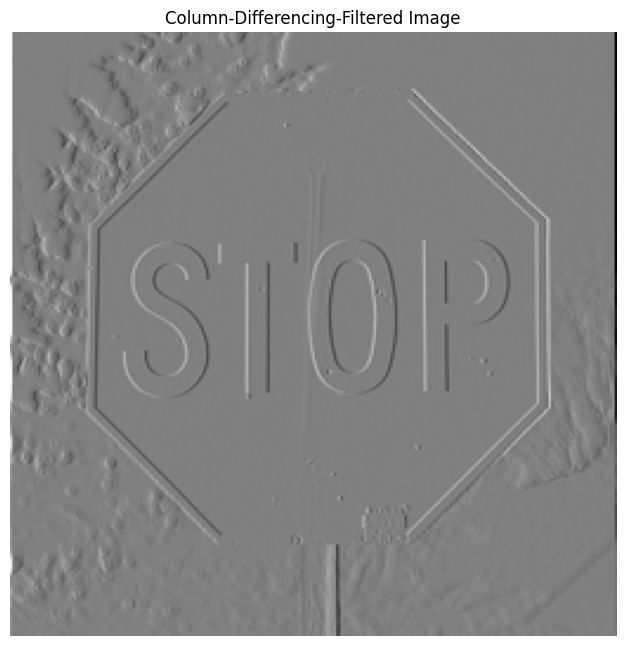

In [26]:
# difference of columns
psf_dif2 = np.ones((1,2))

psf_dif2[0,1]=-1

print('Differencing Point Spread Function')
print(psf_dif2)

filt_dif2 = signal.convolve2d(psf_dif2, stopsign, mode='full')

dispgrayimage(filt_dif2,'Column-Differencing-Filtered Image')

The point-spread function here indicates that the value of each output pixel is given by the difference between the value of the corresponding input image pixel and that of the pixel to the left.  That is, the differencing acts in the horizontal direction, across the columns of the image. 

Note: as in the previous example, differencing produces negative values.  The display rescales all values so the smallest (most negative) value is black and the largest (most positive) value is white.  Zero values are indicated by midtone grey.

1.   What happened to the areas of the image that were constant?
2.   What happened to the edges?
1.   Do all edges produce the same result?
2.   Can you explain why some edges appear to be white, others black, and others are missing?  
1.   Can you explain why the result from the first differencing and second differencing approaches differ? Recall that the first example used differencing across rows (vertically), while this one takes the difference across columns (horizontally).

*In this case the differencing is occuring in the horizontal direction, so vertical edges stand out and horizontal edges are not visible.  The explanations are the same - with interchange of horizontal and vertical terms - as the previous case.*






# Noisy Image

Next we consider the impact of filtering on an image that has been corrupted by noise.

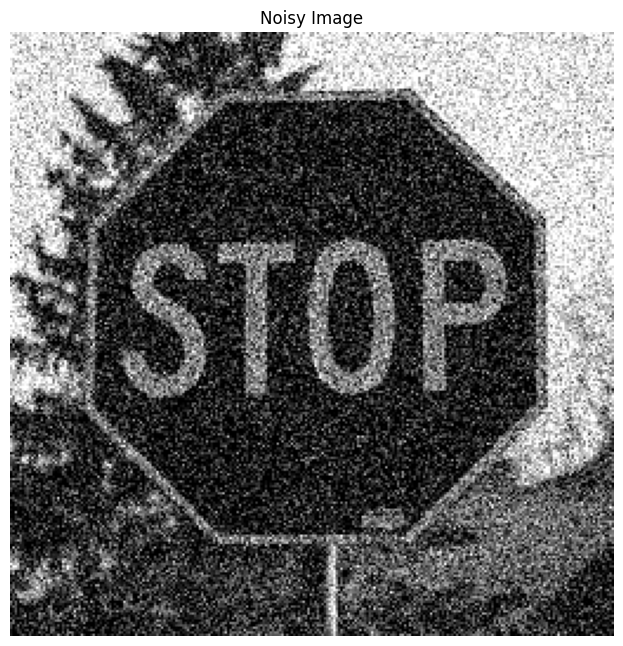

In [27]:
# create noisy version of image

nse_stop = stopsign + 50*np.random.randn(stopsign.shape[0], stopsign.shape[1] )

# restore out of range values to lie in 0 to 255 by truncating for convenience
for i in range(stopsign.shape[0]):
  for j in range(stopsign.shape[1]):
    if nse_stop[i,j]>255:
      nse_stop[i,j] = 255
    if nse_stop[i,j]<0:
      nse_stop[i,j] = 0

# display noisy image

dispgrayimage(nse_stop,'Noisy Image')

*Note that the noise shows up as a speckle character or texture in the image.*

# Averaging Filter on Noisy Image

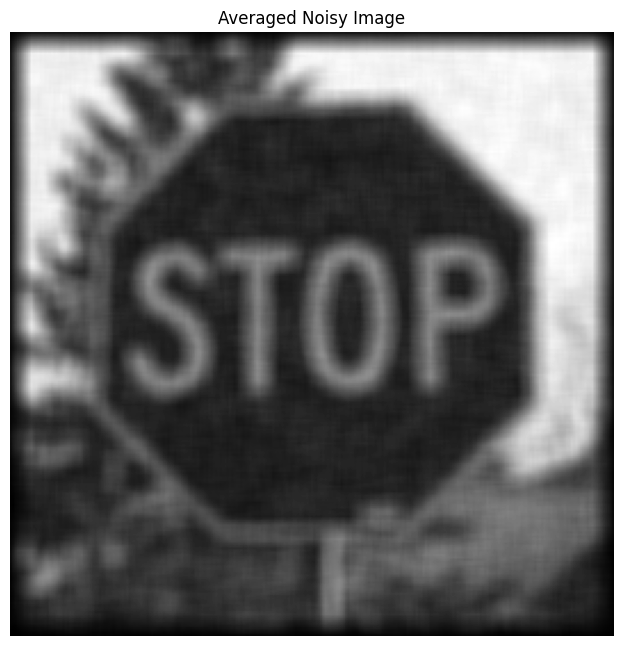

In [28]:
# filter image
filt_av_nse = signal.convolve2d(psf_av, nse_stop, mode='full')

# display filtered noisy image
dispgrayimage(filt_av_nse,'Averaged Noisy Image')


Does the averaging filter change the character of the noise in the image? That is, does the filtered image appear to have less or different noise than the original image? Can you explain why averaging changes the character of the noise? 

*Noise represents unpredictable fluctuations in the values of the image.  Averaging these fluctuations reduces their size and thus smooths out the noise.  Comparison to the average-filtered noise-free image indicates that there still is some noise present, but it is not as visually obvious.  That is, the noise "texture" is much smoother and the flucuations smaller.  While averaging has reduced the noise, it also has blurred the edges in the image, as previously discussed.*

# Explore Further


1.   Investigate how the extent of the averaging PSF is related to the degree of blurring.  For example, you can try replacing 



> ```
psf_av = 0.01*np.ones((10,10))
```
with a 9-pixel average
 ```
psf_av = (1/9)*np.ones((3,3))
```
or a 256-pixel average
```
psf_av = (1/256)*np.ones((16,16))
```


2.   You can also try variations on the differencing filter, such as



> ```
psf_dif = (1/8)*np.array([[-1, -1, -1],[-1, 8, -1],[-1, -1, -1]])
```
This computes each output pixel value as the input value minus the average of the surrounding pixel values.  How do the nature of the edges change relative to simple vertical or horizontal differencing?







Differencing Point Spread Function
[[-0.125 -0.125 -0.125]
 [-0.125  1.    -0.125]
 [-0.125 -0.125 -0.125]]


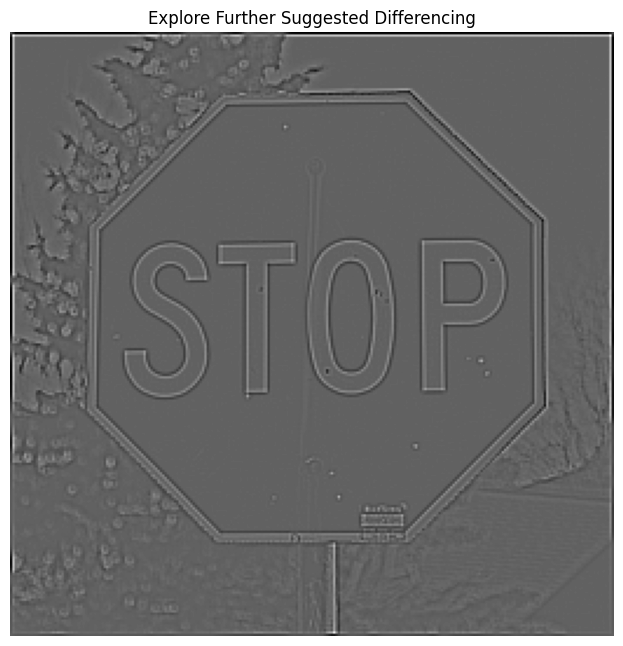

In [29]:
# Differencing filter suggested in the Explore Further section

psf_dif = (1/8)*np.array([[-1, -1, -1],[-1, 8, -1],[-1, -1, -1]])

print('Differencing Point Spread Function')
print(psf_dif)

filt_dif = signal.convolve2d(psf_dif, stopsign, mode='full')

dispgrayimage(filt_dif,'Explore Further Suggested Differencing')